In [1]:
%% MIT 18.03 Lecture 12: Second-Order Damped Vibrations & Root Trajectories
% Description: Simulates the unforced Mass-Spring-Damper system: mx'' + bx' + kx = 0.
%              1) Generates the s-plane Root Diagram showing pole migration as damping b increases.
%              2) Compares time responses across Undamped, Underdamped, Critically Damped, and Overdamped regimes.
%
% % Required Toolboxes:
% %   - Base MATLAB (Core functionality: ODE integration, complex root math).
% % Optional Toolboxes:
% %   - Control System Toolbox (For damp, pzplot, and step response mapping).
%
% % MBD Concept Mapping: Demonstrates characteristic polynomial roots as system poles s = -zeta*w_n +/- j*w_d.
% %                      Illustrates the trade-off between decay envelope rate and oscillatory frequency.


clear; clc; close all;


%% 1. Baseline Physical Parameters
m = 1.0;            % Mass (kg)
k = 4.0;            % Spring constant (N/m) -> w_n = sqrt(k/m) = 2.0 rad/s
omega_n = sqrt(k/m);
b_crit = 2 * sqrt(m * k); % Critical damping threshold: b_crit = 4.0 N*s/m


fprintf('=== Physical Plant Natural Characteristics ===\n');

=== Physical Plant Natural Characteristics ===

In [2]:
fprintf('Mass (m)                 : %.2f kg\n', m);

Mass (m)                 : 1.00 kg

In [3]:
fprintf('Stiffness (k)            : %.2f N/m\n', k);

Stiffness (k)            : 4.00 N/m

In [4]:
fprintf('Natural Frequency (w_n)  : %.4f rad/s\n', omega_n);

Natural Frequency (w_n)  : 2.0000 rad/s

In [5]:
fprintf('Critical Damping (b_crit): %.4f N*s/m\n', b_crit);

Critical Damping (b_crit): 4.0000 N*s/m

In [6]:
fprintf('==============================================\n\n');


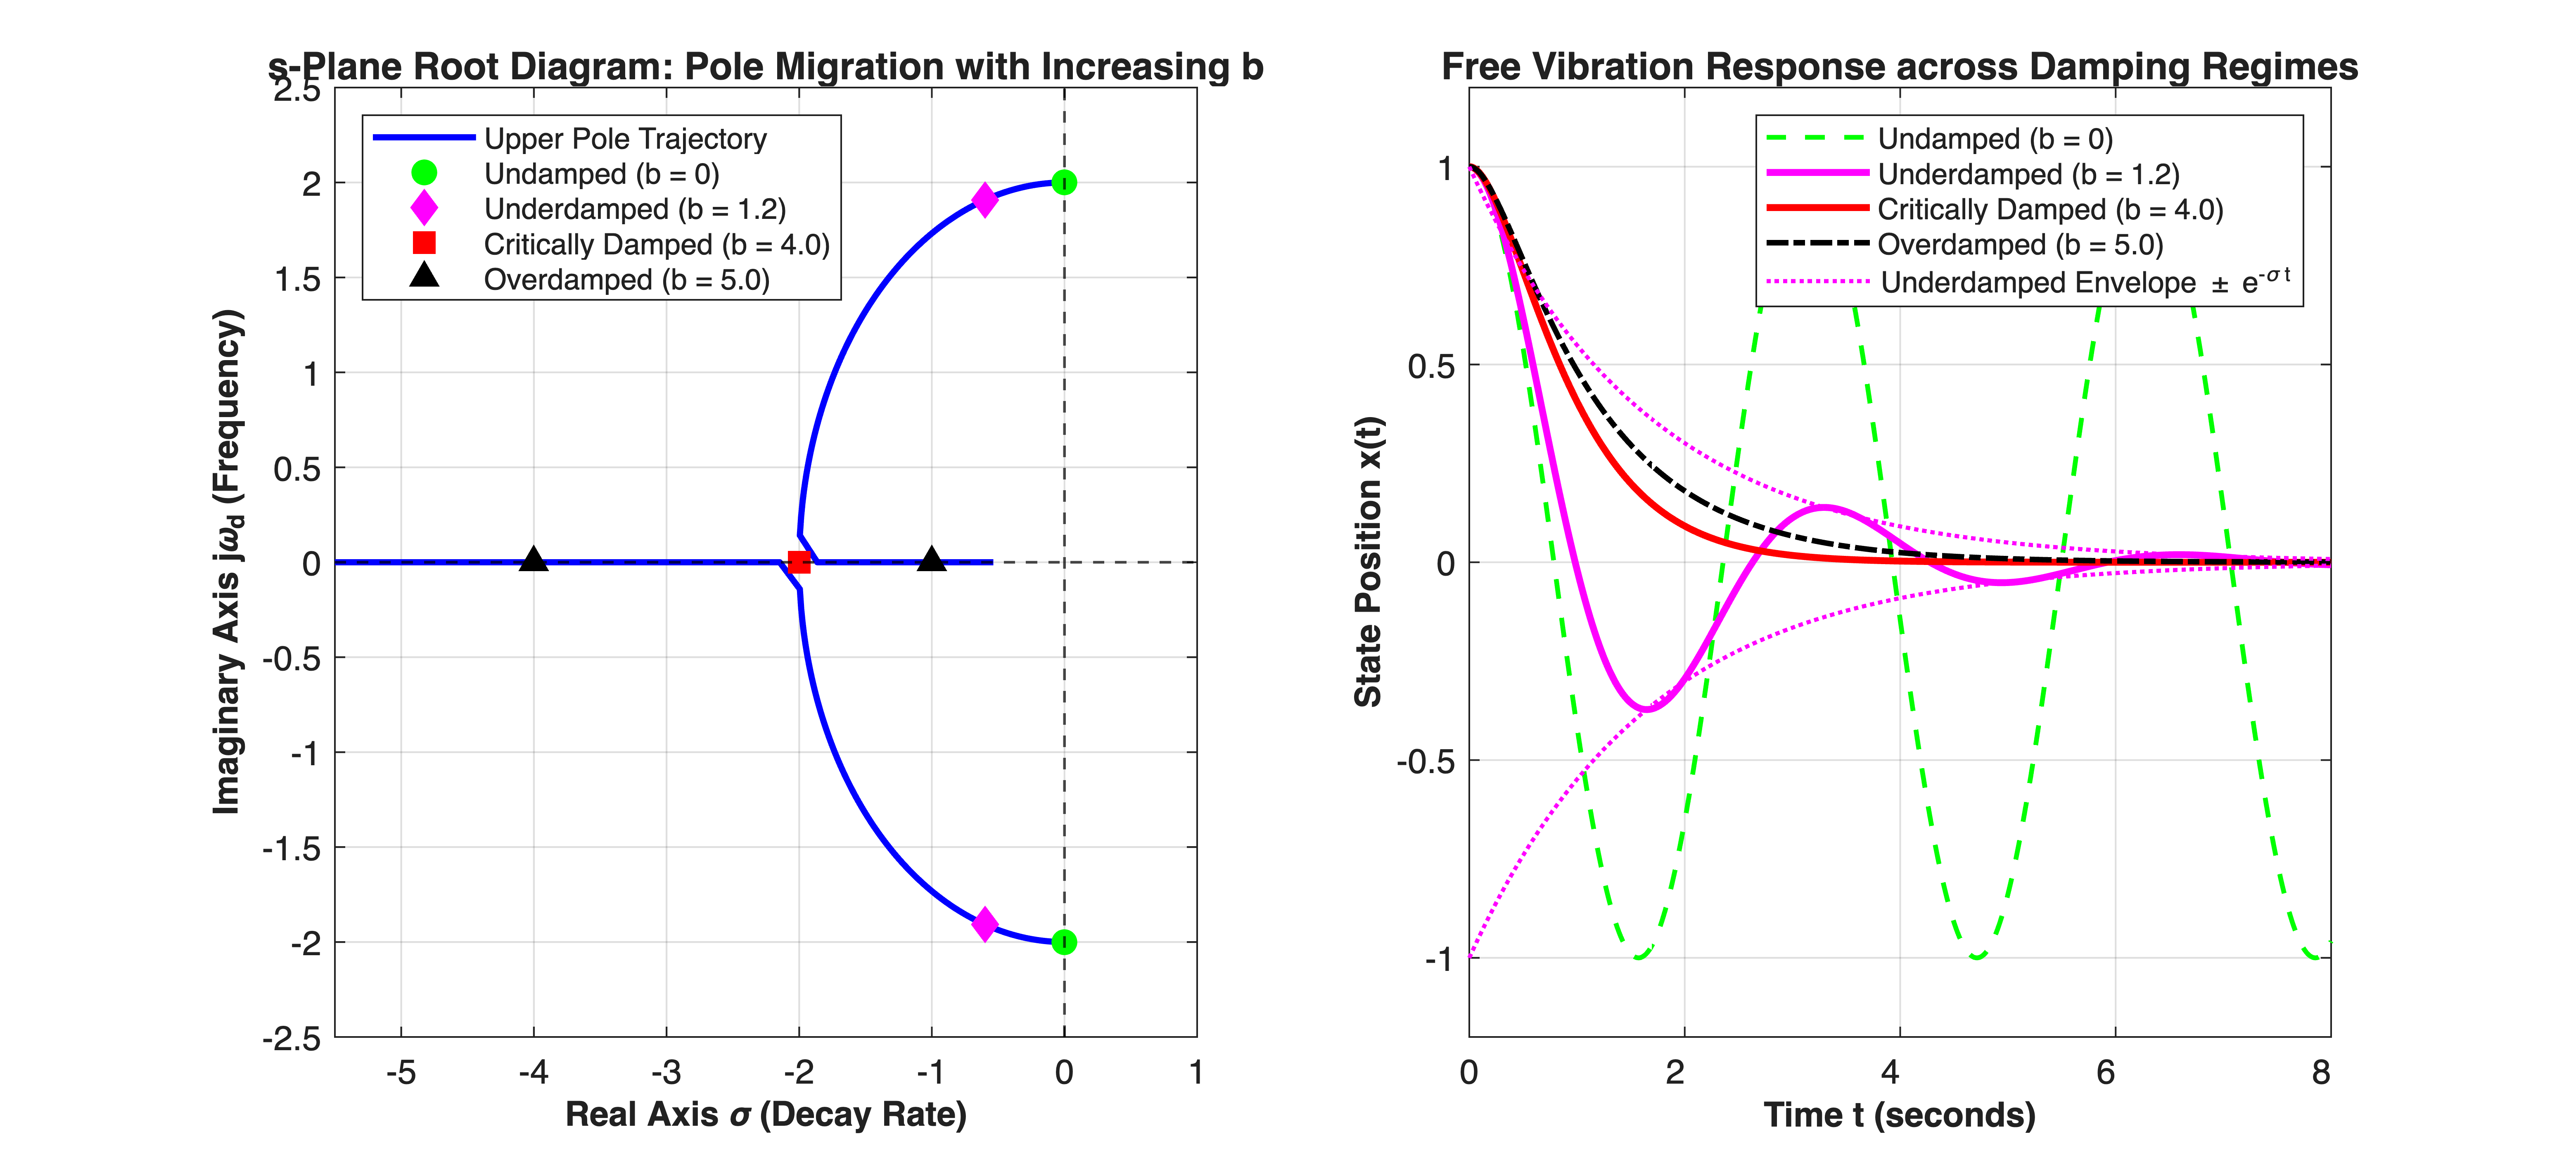

In [7]:


%% 2. Root Diagram (s-plane Migration as b Sweeps from 0 to 8)
b_sweep = linspace(0, 8.0, 400);
poles_sweep = zeros(length(b_sweep), 2);


for idx = 1:length(b_sweep)
    b_val = b_sweep(idx);
    disc = (b_val / (2*m))^2 - (k / m);
    if disc <= 0
        w_d = sqrt(-disc);
        poles_sweep(idx, 1) = -b_val / (2*m) + 1i * w_d;
        poles_sweep(idx, 2) = -b_val / (2*m) - 1i * w_d;
    else
        delta_real = sqrt(disc);
        poles_sweep(idx, 1) = -b_val / (2*m) + delta_real;
        poles_sweep(idx, 2) = -b_val / (2*m) - delta_real;
    end
end


figure('Color', [1 1 1], 'Position', [100, 100, 1150, 520]);


% Subplot 1: Root Diagram (s-Plane Trajectory)
subplot(1, 2, 1);
hold on; grid on; box on;


% Draw real and imaginary axes
xline(0, 'k--', 'LineWidth', 0.8, 'HandleVisibility', 'off');
yline(0, 'k--', 'LineWidth', 0.8, 'HandleVisibility', 'off');


% Plot pole locus lines
plot(real(poles_sweep(:, 1)), imag(poles_sweep(:, 1)), 'b-', 'LineWidth', 1.8, ...
     'DisplayName', 'Upper Pole Trajectory');
plot(real(poles_sweep(:, 2)), imag(poles_sweep(:, 2)), 'b-', 'LineWidth', 1.8, ...
     'HandleVisibility', 'off');


% Highlight benchmark poles
pole_undamped   = [0 + 1i*omega_n, 0 - 1i*omega_n];
pole_under      = roots([m, 1.2, k]); % b = 1.2
pole_critical   = [-b_crit / (2*m), -b_crit / (2*m)];
pole_overdamped = roots([m, 5.0, k]); % b = 5.0


plot(real(pole_undamped), imag(pole_undamped), 'go', 'MarkerFaceColor', 'g', 'MarkerSize', 7, ...
     'DisplayName', 'Undamped (b = 0)');
plot(real(pole_under), imag(pole_under), 'md', 'MarkerFaceColor', 'm', 'MarkerSize', 7, ...
     'DisplayName', 'Underdamped (b = 1.2)');
plot(real(pole_critical), imag(pole_critical), 'rs', 'MarkerFaceColor', 'r', 'MarkerSize', 8, ...
     'DisplayName', 'Critically Damped (b = 4.0)');
plot(real(pole_overdamped), imag(pole_overdamped), 'k^', 'MarkerFaceColor', 'k', 'MarkerSize', 7, ...
     'DisplayName', 'Overdamped (b = 5.0)');


xlabel('Real Axis \sigma (Decay Rate)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Imaginary Axis j\omega_d (Frequency)', 'FontSize', 10, 'FontWeight', 'bold');
title('s-Plane Root Diagram: Pole Migration with Increasing b', 'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8.5);
xlim([-5.5, 1.0]);
ylim([-2.5, 2.5]);


%% 3. Time-Domain Free Response Comparison
t_eval = linspace(0, 8.0, 600);
x0 = 1.0; v0 = 0.0; % Initial conditions: unit displacement, released from rest


% State-space ODE function builder: d/dt [x; v] = [v; -k/m*x - b/m*v]
get_ode = @(b_in) @(t, X) [X(2); -(k/m)*X(1) - (b_in/m)*X(2)];
opts = odeset('RelTol', 1e-8, 'AbsTol', 1e-10);


[~, X_undamped] = ode45(get_ode(0.0),   t_eval, [x0; v0], opts);
[~, X_under]    = ode45(get_ode(1.2),   t_eval, [x0; v0], opts);
[~, X_crit]     = ode45(get_ode(b_crit),t_eval, [x0; v0], opts);
[~, X_over]     = ode45(get_ode(5.0),   t_eval, [x0; v0], opts);


% Subplot 2: Temporal Trajectories
subplot(1, 2, 2);
hold on; grid on; box on;


plot(t_eval, X_undamped(:, 1), 'g--', 'LineWidth', 1.4, 'DisplayName', 'Undamped (b = 0)');
plot(t_eval, X_under(:, 1),    'm-',  'LineWidth', 2.0, 'DisplayName', 'Underdamped (b = 1.2)');
plot(t_eval, X_crit(:, 1),     'r-',  'LineWidth', 2.0, 'DisplayName', 'Critically Damped (b = 4.0)');
plot(t_eval, X_over(:, 1),     'k-.', 'LineWidth', 1.6, 'DisplayName', 'Overdamped (b = 5.0)');


% Envelope for underdamped case
b_u = 1.2;
decay_env = x0 * exp(-b_u / (2*m) * t_eval);
plot(t_eval, decay_env, 'm:', 'LineWidth', 1.2, 'DisplayName', 'Underdamped Envelope \pm e^{-\sigma t}');
plot(t_eval, -decay_env, 'm:', 'LineWidth', 1.2, 'HandleVisibility', 'off');


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('State Position x(t)', 'FontSize', 10, 'FontWeight', 'bold');
title('Free Vibration Response across Damping Regimes', 'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northeast', 'FontSize', 8.5);
xlim([0, 8.0]);
ylim([-1.2, 1.2]);